In [5]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from typing import Iterable, Optional, Sequence, Tuple

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from parse_eval_logs import (
    agg_rs_results,
)
from tqdm import tqdm

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "pgf.rcfonts": False,
})


LOGS_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [69]:
# Each point: (x, [rep1, rep2, ...])
Point = Tuple[float, Sequence[float]]
Series = Sequence[Point]

def plot_xy_mean_se(
    *series: Series,
    labels: Optional[Sequence[str]] = None,
    title: str = "",
    xlabel: str = "x",
    ylabel: str = "y",
    logx: bool = False,
    symlog_linthresh: float = 1.0,
    markers: bool = True,
    capsize: float = 3.0,
    save_figure = False,
    figure_file_name: str = "figure"
):
    """
    Plot one or more series of (x, [y1, y2, ...]) points as mean ± SE.

    Args:
        *series: Any number of sequences of (x, [values]) pairs.
        labels: Optional labels for legend (same order as series).
        logx: If True, use 'symlog' for x-axis so x=0 is allowed.
        symlog_linthresh: Linear threshold around 0 for symlog.
        markers: If True, draw point markers.
        capsize: Size of errorbar caps.

    Returns:
        (fig, ax)
    """
    fig, ax = plt.subplots()
    for i, s in enumerate(series):
        if not s:
            continue
        # Sort by x and compute mean & SE per point
        s_sorted = sorted(s, key=lambda p: p[0])
        xs, means, ses = [], [], []
        for x, vals in s_sorted:
            v = np.asarray(list(vals), dtype=float)
            if v.size == 0:
                continue
            m = float(np.mean(v))
            se = float(np.std(v, ddof=1) / np.sqrt(v.size)) if v.size > 1 else 0.0
            xs.append(x); means.append(m); ses.append(se)

        label = (labels[i] if labels and i < len(labels) else f"series {i+1}")
        fmt = "-o" if markers else "-"
        ax.errorbar(xs, means, yerr=ses, fmt=fmt, capsize=capsize, label=label)

    if logx:
        ax.set_xscale("symlog", linthresh=symlog_linthresh)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if len(series) > 1:
        ax.legend()
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

    if save_figure:
        fig.savefig(f"paper_plots/{figure_file_name}.pdf")

    return fig, ax


# Logs loading

In [ ]:
padding_length = ["0", "1000","5000","10000", "50000","100000","200000", "800000"]
padding_types = [ "before","after", "around"]
task_types = ["benign", "harm"]

In [8]:
sonoma_model_types = ["sonoma-dusk-alpha", "sonoma-sky-alpha"]

# sonoma[harm/benign][after/before/around][sky/dusk][padding_length]
sonoma_random_paddings = {
    task_type: {
        pad_type: {k: {}
            for k in sonoma_model_types}
        for pad_type in padding_types}
    for task_type in task_types
}
print(sonoma_random_paddings)

for task_type in task_types:
    for pad_type in tqdm(padding_types, desc=f"Processing {task_type}"):
        for model in sonoma_model_types:
            for pad_len in padding_length:
                if pad_len == "0":
                    dir_name = f"{pad_len}_after" # for 0 padding we have common run        
                else:
                    dir_name = f"{pad_len}_{pad_type}"
                
                try:
                    sonoma_random_paddings[task_type][pad_type][model][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/{model}/test_hint_det_prompt")
                except Exception as e:
                    print(f"Error: {f'{task_type}/sonoma_random_padding/{dir_name}/{model}/test_hint_det_prompt'}")

# sonoma_harm_rand_pad = sonoma_random_paddings["harm"]
# sonoma_benign_rand_pad = sonoma_random_paddings["benign"]

{'benign': {'before': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'around': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}, 'harm': {'before': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'around': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}}


Processing benign:   0%|          | 0/3 [00:00<?, ?it/s]

Error: benign/sonoma_random_padding/5000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/10000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/100000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/800000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/5000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/10000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/100000_before/sonoma-sky-alpha/test_hint_det_prompt


Processing benign:  33%|███▎      | 1/3 [00:43<01:27, 43.68s/it]

Error: benign/sonoma_random_padding/800000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/800000_after/sonoma-dusk-alpha/test_hint_det_prompt


Processing benign:  67%|██████▋   | 2/3 [01:45<00:54, 54.18s/it]

... (7 outputs left out)

Processing harm:  67%|██████▋   | 2/3 [01:57<01:01, 61.08s/it]

Error: harm/sonoma_random_padding/800000_after/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/5000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/10000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/100000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/800000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/5000_around/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/10000_around/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/100000_around/sonoma-sky-alpha/test_hint_det_prompt


Processing harm: 100%|██████████| 3/3 [02:46<00:00, 55.62s/it]

Error: harm/sonoma_random_padding/800000_around/sonoma-sky-alpha/test_hint_det_prompt


In [46]:
# [harm/benign][after/before/around][sky/dusk][padding_length]
gpt_nano_random_paddings = {task_type: { pad_type: {"gpt-4.1-nano": {}} for pad_type in padding_types} for task_type in task_types}
print(gpt_nano_random_paddings)

for task_type in task_types:
    for pad_type in tqdm(padding_types, desc=f"Processing {task_type}"):
        for pad_len in padding_length:
            if pad_len == "800000":
                continue
            if pad_len == "0":
                dir_name = f"{pad_len}_after" # for 0 padding we have common run        
            else:
                dir_name = f"{pad_len}_{pad_type}"
            try:
                gpt_nano_random_paddings[task_type][pad_type]["gpt-4.1-nano"][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")
            except Exception as e:
                print(f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

{'benign': {'before': {'gpt-4.1-nano': {}}, 'after': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}}, 'harm': {'before': {'gpt-4.1-nano': {}}, 'after': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}}}


Processing benign:   0%|          | 0/3 [00:00<?, ?it/s]

benign/random_padding/1000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/5000_before/gpt_4.1_nano/test_hint_det_prompt


Processing benign:  33%|███▎      | 1/3 [00:05<00:10,  5.26s/it]

benign/random_padding/50000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/100000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/200000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/50000_after/gpt_4.1_nano/test_hint_det_prompt


Processing benign:  67%|██████▋   | 2/3 [00:25<00:13, 13.86s/it]

... (5 outputs left out)

Processing harm:  33%|███▎      | 1/3 [00:33<01:06, 33.11s/it]

harm/random_padding/200000_before/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/50000_after/gpt_4.1_nano/test_hint_det_prompt


Processing harm: 100%|██████████| 3/3 [01:05<00:00, 21.96s/it]

harm/random_padding/50000_around/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/100000_around/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/200000_around/gpt_4.1_nano/test_hint_det_prompt


In [ ]:
# [harm/benign][after/before/around][sky/dusk][padding_length]
gpt_nano_irrel_paddings = {task_type: { pad_type: {"gpt-4.1-nano": {}} for pad_type in padding_types} for task_type in task_types}
print(gpt_nano_random_paddings)

for task_type in task_types:
    for pad_type in tqdm(padding_types, desc=f"Processing {task_type}"):
        for pad_len in padding_length:
            if pad_len == "800000":
                continue
            if pad_len == "0":
                dir_name = f"{pad_len}_after" # for 0 padding we have common run        
            else:
                dir_name = f"{pad_len}_{pad_type}"
            try:
                gpt_nano_random_paddings[task_type][pad_type]["gpt-4.1-nano"][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")
            except Exception as e:
                print(f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

# Refusal rate plot

In [101]:
# sonoma
metrics_refusals = [
    # ("sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
    ("sonoma sky rand before",[(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
    # ("sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-dusk-alpha"].items()]),
    ("sonoma sky rand after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-sky-alpha"].items()]),
    # ("sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["around"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in sonoma_random_paddings["harm"]["around"]["sonoma-sky-alpha"].items()]),
    ("gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["around"]["gpt-4.1-nano"].items()]),
]

# conv_metrics = []
# for m in metrics:
#     conv_m = []
#     for k, mm in m:
#         conv_m.append((int(k.split("_")[0]), np.mean(mm).item()))
#     conv_metrics.append(conv_m)
#     # print(conv_m)

(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

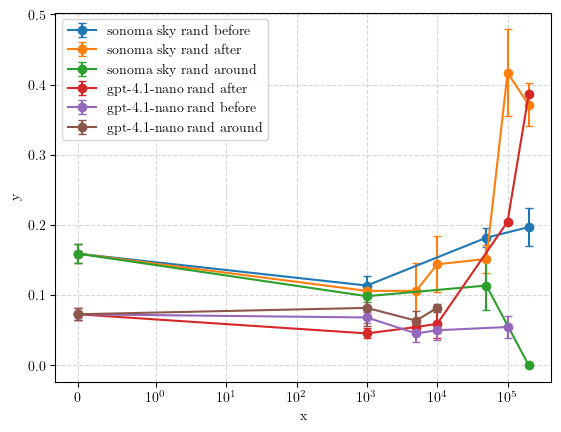

In [100]:
plot_xy_mean_se(
    *[m for _,m in metrics_refusals],
    labels=[l for l,_ in metrics_refusals],
    logx=True,
    save_figure=True,
    figure_file_name="figure2b"
)

# harm results

In [92]:
metrics_score = [
    # ("sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
    # ("sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-sky-alpha"].items()]),
    # ("sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
    ("gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["around"]["gpt-4.1-nano"].items()]),
    # ("benign sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
    # ("benign gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["after"]["gpt-4.1-nano"].items()]),
    # ("benign gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["before"]["gpt-4.1-nano"].items()]),
    # ("benign gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["around"]["gpt-4.1-nano"].items()]),
]

# metrics_score = [
#     # ("sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
#     # ("sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
#     ("sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-dusk-alpha"].items()]),
#     ("sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-sky-alpha"].items()]),
#     # ("sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
#     # ("sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
#     ("gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
#     # ("gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
#     # ("gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["harm"]["around"]["gpt-4.1-nano"].items()]),
#     # ("benign sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
#     # ("benign sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
#     ("benign sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-dusk-alpha"].items()]),
#     ("benign sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-sky-alpha"].items()]),
#     # ("benign sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
#     # ("benign sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
#     ("benign gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["after"]["gpt-4.1-nano"].items()]),
#     # ("benign gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["before"]["gpt-4.1-nano"].items()]),
#     # ("benign gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["around"]["gpt-4.1-nano"].items()]),
# ]



(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='padding size in tokens', ylabel='score'>)

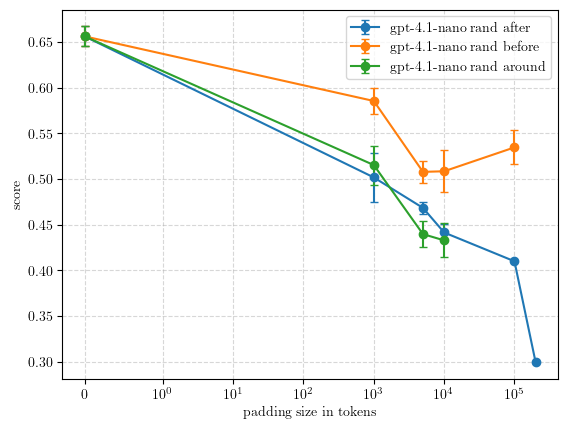

In [ ]:
plot_xy_mean_se(
    *[m for _,m in metrics_score],
    labels=[l for l,_ in metrics_score],
    logx=True,
    xlabel="padding size in tokens",
    ylabel="score",
    save_figure = True,
    figure_file_name="figure2a"
)